# Sumativa 3: Evaluación, bootstrap y sensibilidad a la imputación

**Asignatura:** Estadística Computacional  
**Integrantes:** Hernán Saavedra, Lenin Morales y Rodrigo Gómez  
**Responsable de este notebook:** Rodrigo Gómez  
**Dataset:** IBM HR Employee Attrition

## Objetivo

Evaluar las especificaciones M1, M2 y M3 desarrolladas por Lenin,
junto con M2c, variante corregida tras los diagnósticos y seleccionada
previamente mediante análisis de entrenamiento.

Se presentan métricas, matrices de confusión y curvas ROC en
entrenamiento y prueba, y se compara el desempeño con Formativa 2.

La estabilidad de M2c se examina mediante 10.000 remuestras bootstrap,
repitiendo la preparación y el ajuste. Se comparan intervalos
percentiles con intervalos HC0 y se evalúa la conservación del signo.

Finalmente, se comparan eliminación, mediana y regresión para M2c
y, como complemento, para M1, que incluye ingreso. La evaluación
considera los conjuntos disponibles y el subconjunto común de prueba.

## Ejecución

Ejecutar las celdas en orden desde la raíz del repositorio o desde
esta carpeta. Se requieren las funciones y los ejecutores de S3/src.

El bootstrap se ejecuta en procesos independientes y guarda lotes
reanudables. Si existen los 10.000 intentos de la configuración actual,
se recuperan; de lo contrario, se continúa hasta completarlos.

## 1: Importación de Librerías y Carga de Datos

In [1]:
from pathlib import Path
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm

from threadpoolctl import threadpool_limits

limite_hilos = threadpool_limits(limits=1)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    roc_curve,
)

# Localizar el repositorio.
RAIZ = next(
    (
        carpeta
        for carpeta in [Path.cwd(), *Path.cwd().parents]
        if (
            carpeta / "datos" / "WA_Fn-UseC_-HR-Employee-Attrition.csv"
        ).is_file()
    ),
    None,
)

if RAIZ is None:
    raise FileNotFoundError("No se encontró la raíz del repositorio.")

DIRECTORIO_S3 = RAIZ / "S3"
RESULTADOS = DIRECTORIO_S3 / "resultados"
FIGURAS = DIRECTORIO_S3 / "figuras"

RESULTADOS.mkdir(parents=True, exist_ok=True)
FIGURAS.mkdir(parents=True, exist_ok=True)

# Reutilizar exactamente los procedimientos de Lenin.
sys.path.insert(0, str(DIRECTORIO_S3 / "src"))

from lenin_modelado import (
    ImputadorRegresion,
    PreparadorDiseno,
    ajustar_logit,
    codificar_objetivo,
    pesos_balanceados,
    reajustar_modelo_final,
    tabla_coeficientes,
)

config_final = json.loads(
    (RESULTADOS / "lenin_configuracion_modelo_final.json")
    .read_text(encoding="utf-8")
)

SEMILLA = config_final["semilla"]
UMBRAL = config_final["umbral"]
ESPECIFICACIONES = config_final["especificaciones"]
MODELO_FINAL = config_final["modelo_seleccionado"]

df_mcar = pd.read_csv(
    RAIZ / config_final["datos_MCAR"]
).set_index("EmployeeNumber")

particion = pd.read_csv(
    RAIZ / config_final["particion"]
).set_index("EmployeeNumber")

train_mcar = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Entrenamiento"]
].copy()

test_mcar = df_mcar.loc[
    particion.index[particion["Conjunto"] == "Prueba"]
].copy()

y_train = codificar_objetivo(train_mcar["Attrition"])
y_test = codificar_objetivo(test_mcar["Attrition"])

assert len(train_mcar) == 1029
assert len(test_mcar) == 441
assert set(train_mcar.index).isdisjoint(test_mcar.index)

print("Modelo final seleccionado por Lenin:", MODELO_FINAL)
print("Entrenamiento:", len(train_mcar))
print("Prueba:", len(test_mcar))

display(pd.DataFrame([
    {
        "Modelo": nombre,
        "Predictores": ", ".join(variables),
    }
    for nombre, variables in ESPECIFICACIONES.items()
]))

Modelo final seleccionado por Lenin: M2c
Entrenamiento: 1029
Prueba: 441


,Modelo,Predictores
0,M1,"OverTime, MonthlyIncome, YearsAtCompany, JobSa..."
1,M2,"OverTime, YearsAtCompany, JobSatisfaction, Age..."
2,M3,"OverTime, YearsAtCompany, JobSatisfaction, Age..."
3,M2c,"OverTime, log1p_YearsAtCompany, JobSatisfactio..."


## 2 (Punto 1): Evaluación de los Modelos en Entrenamiento y Prueba

In [2]:
def calcular_metricas(y_real, probabilidades):
    predicciones = (np.asarray(probabilidades) >= UMBRAL).astype(int)
    tn, fp, fn, tp = confusion_matrix(
        y_real, predicciones, labels=[0, 1]
    ).ravel()

    return {
        "Registros": len(y_real),
        "Accuracy": accuracy_score(y_real, predicciones),
        "Precision": precision_score(
            y_real, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_real, predicciones, zero_division=0
        ),
        "F1": f1_score(y_real, predicciones, zero_division=0),
        "AUC": roc_auc_score(y_real, probabilidades),
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
    }


# Ajustar la imputación solo con entrenamiento.
imputador = ImputadorRegresion(
    config_final["imputacion"]["variable"],
    config_final["imputacion"]["predictores"],
).ajustar(train_mcar)

train_imp = imputador.transformar(train_mcar)
test_imp = imputador.transformar(test_mcar)

pesos_train = pesos_balanceados(y_train)

ajustes = {}
predicciones_modelos = {}
filas_metricas = []
tablas_coeficientes = []

for nombre, variables in ESPECIFICACIONES.items():
    preparador = PreparadorDiseno(variables).ajustar(train_imp)
    X_train = preparador.transformar(train_imp)
    X_test = preparador.transformar(test_imp)

    for ponderacion, pesos in [
        ("Sin ponderar", None),
        ("Ponderado", pesos_train),
    ]:
        resultado = ajustar_logit(X_train, y_train, pesos)

        clave = (nombre, ponderacion)
        ajustes[clave] = {
            "resultado": resultado,
            "preparador": preparador,
        }

        tabla = tabla_coeficientes(resultado).reset_index()
        tabla.insert(0, "Ponderacion", ponderacion)
        tabla.insert(0, "Modelo", nombre)
        tablas_coeficientes.append(tabla)

        for conjunto, X, y in [
            ("Entrenamiento", X_train, y_train),
            ("Prueba", X_test, y_test),
        ]:
            probabilidades = resultado.predict(X)

            assert X.index.equals(y.index)
            assert np.isfinite(probabilidades).all()
            assert probabilidades.between(0, 1).all()

            predicciones_modelos[
                (nombre, ponderacion, conjunto)
            ] = probabilidades

            filas_metricas.append({
                "Modelo": nombre,
                "Ponderacion": ponderacion,
                "Conjunto": conjunto,
                **calcular_metricas(y, probabilidades),
            })

metricas_modelos = pd.DataFrame(filas_metricas)

metricas_modelos.to_csv(
    RESULTADOS / "rodrigo_metricas_modelos.csv",
    index=False,
)

pd.concat(tablas_coeficientes, ignore_index=True).to_csv(
    RESULTADOS / "rodrigo_coeficientes_modelos.csv",
    index=False,
)

# Comprobar que reproducimos las probabilidades finales de Lenin.
probabilidades_lenin = pd.read_csv(
    RESULTADOS / "lenin_probabilidades_prueba.csv",
    index_col="EmployeeNumber",
)

np.testing.assert_allclose(
    predicciones_modelos[
        (MODELO_FINAL, "Ponderado", "Prueba")
    ].loc[probabilidades_lenin.index],
    probabilidades_lenin["Probabilidad_salida"],
    rtol=1e-7,
    atol=1e-10,
)

display(
    metricas_modelos.loc[
        (metricas_modelos["Conjunto"] == "Prueba")
        & (metricas_modelos["Ponderacion"] == "Ponderado")
    ].round(4)
)

print("Probabilidades del modelo final coinciden con las de Lenin.")

,Modelo,Ponderacion,Conjunto,Registros,Accuracy,Precision,Recall,F1,AUC,TN,FP,FN,TP
3,M1,Ponderado,Prueba,441,0.7302,0.3421,0.7324,0.4664,0.7734,270,100,19,52
7,M2,Ponderado,Prueba,441,0.7234,0.3311,0.7042,0.4505,0.7614,269,101,21,50
11,M3,Ponderado,Prueba,441,0.7234,0.3241,0.6620,0.4352,0.7463,272,98,24,47
15,M2c,Ponderado,Prueba,441,0.7506,0.3636,0.7324,0.4860,0.7722,279,91,19,52


Probabilidades del modelo final coinciden con las de Lenin.


## Matrices de confusión y curvas ROC

Se muestran los modelos ponderados con umbral 0,5. Las matrices de
confusión distinguen salidas detectadas, salidas omitidas y falsas
alarmas, tanto en entrenamiento como en prueba.

Las curvas ROC comparan la capacidad de discriminación a través de
distintos umbrales. La evaluación de prueba se utiliza para describir
el desempeño de las especificaciones previamente seleccionadas.

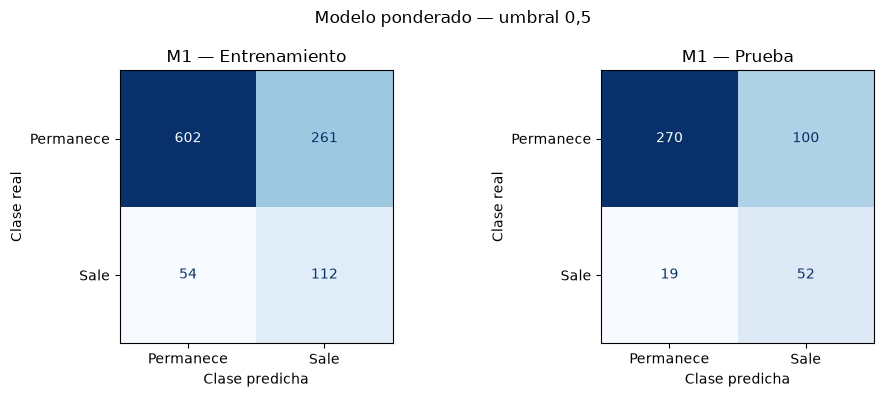

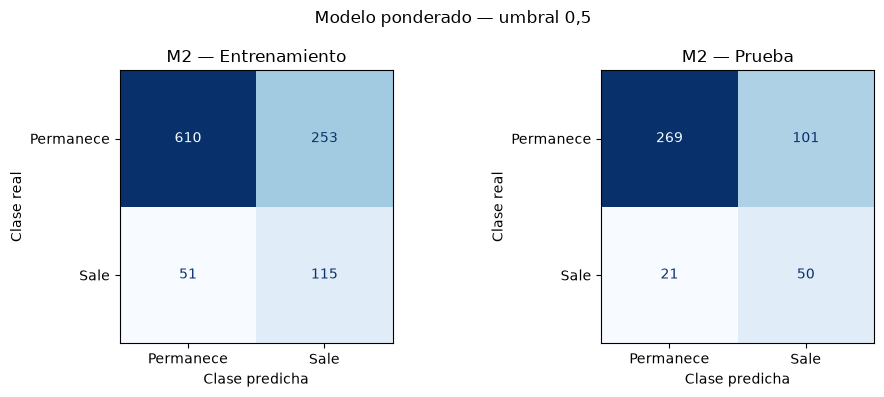

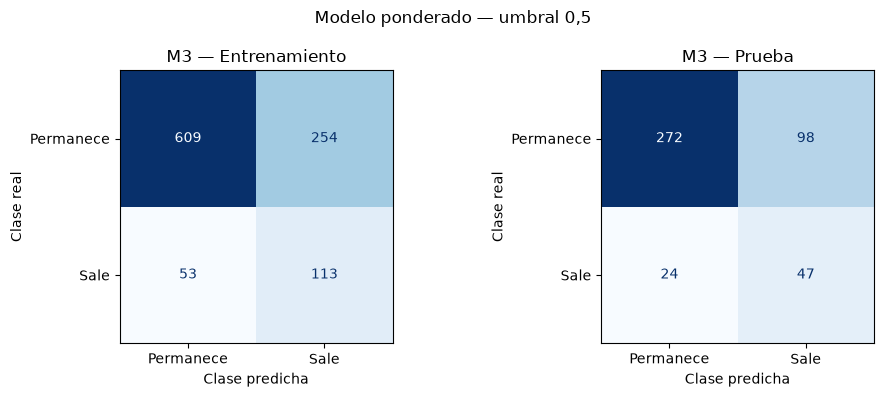

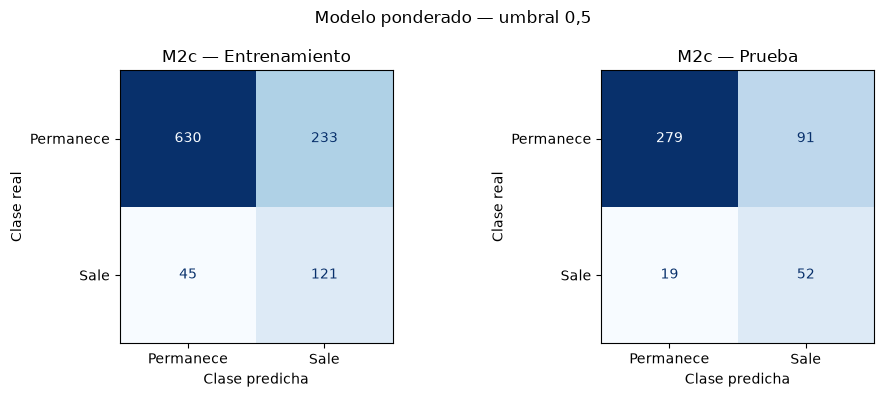

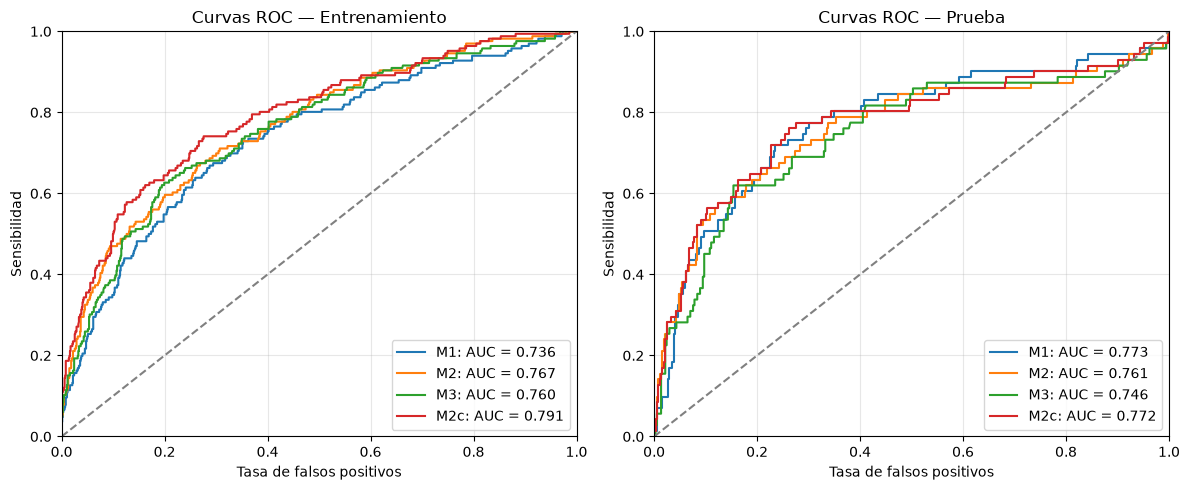

Matrices de confusión y curvas ROC guardadas.


In [3]:
from sklearn.metrics import ConfusionMatrixDisplay

# Un gráfico por modelo, con entrenamiento y prueba.
for nombre in ESPECIFICACIONES:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    for ax, conjunto, y in [
        (axes[0], "Entrenamiento", y_train),
        (axes[1], "Prueba", y_test),
    ]:
        probabilidades = predicciones_modelos[
            (nombre, "Ponderado", conjunto)
        ]
        predicciones = (probabilidades >= UMBRAL).astype(int)

        ConfusionMatrixDisplay.from_predictions(
            y,
            predicciones,
            labels=[0, 1],
            display_labels=["Permanece", "Sale"],
            cmap="Blues",
            colorbar=False,
            ax=ax,
        )

        ax.set_title(f"{nombre} — {conjunto}")
        ax.set_xlabel("Clase predicha")
        ax.set_ylabel("Clase real")

    fig.suptitle("Modelo ponderado — umbral 0,5")
    fig.tight_layout()

    fig.savefig(
        FIGURAS / f"rodrigo_confusion_{nombre}.png",
        dpi=300,
        bbox_inches="tight",
    )
    plt.show()
    plt.close(fig)

# Comparación ROC de los cuatro modelos.
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, conjunto, y in [
    (axes[0], "Entrenamiento", y_train),
    (axes[1], "Prueba", y_test),
]:
    for nombre in ESPECIFICACIONES:
        probabilidades = predicciones_modelos[
            (nombre, "Ponderado", conjunto)
        ]

        fpr, tpr, _ = roc_curve(y, probabilidades)
        area = roc_auc_score(y, probabilidades)

        ax.plot(
            fpr, tpr,
            label=f"{nombre}: AUC = {area:.3f}",
        )

    ax.plot([0, 1], [0, 1], "--", color="gray")
    ax.set(
        xlabel="Tasa de falsos positivos",
        ylabel="Sensibilidad",
        title=f"Curvas ROC — {conjunto}",
        xlim=(0, 1),
        ylim=(0, 1),
    )
    ax.legend()
    ax.grid(alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURAS / "rodrigo_roc_modelos.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

print("Matrices de confusión y curvas ROC guardadas.")

## 3: Comparación con la Referencia de F2

In [4]:
probabilidades_f2 = pd.read_csv(
    RAIZ / "Formativa2" / "resultados" / "probabilidades_prueba.csv",
    index_col="EmployeeNumber",
)

assert probabilidades_f2.index.is_unique
assert set(probabilidades_f2.index) == set(y_test.index)

comparacion_f2 = pd.DataFrame([
    {
        "Modelo": "F2: sin ponderar",
        **calcular_metricas(
            y_test,
            probabilidades_f2.loc[y_test.index, "Probabilidad_salida"],
        ),
    },
    {
        "Modelo": "S3 M2c: sin ponderar",
        **calcular_metricas(
            y_test,
            predicciones_modelos[
                (MODELO_FINAL, "Sin ponderar", "Prueba")
            ],
        ),
    },
    {
        "Modelo": "S3 M2c: ponderado",
        **calcular_metricas(
            y_test,
            predicciones_modelos[
                (MODELO_FINAL, "Ponderado", "Prueba")
            ],
        ),
    },
])

comparacion_f2.to_csv(
    RESULTADOS / "rodrigo_comparacion_F2_S3.csv",
    index=False,
)

display(comparacion_f2.round(4))

diferencia_recall = (
    comparacion_f2.iloc[2]["Recall"]
    - comparacion_f2.iloc[0]["Recall"]
) * 100

print(
    f"Variación de recall frente a F2: "
    f"{diferencia_recall:.2f} puntos porcentuales."
)

,Modelo,Registros,Accuracy,Precision,Recall,F1,AUC,TN,FP,FN,TP
0,F2: sin ponderar,441,0.8435,0.6667,0.0563,0.1039,0.7724,368,2,67,4
1,S3 M2c: sin ponderar,441,0.8549,0.6296,0.2394,0.3469,0.7728,360,10,54,17
2,S3 M2c: ponderado,441,0.7506,0.3636,0.7324,0.4860,0.7722,279,91,19,52


Variación de recall frente a F2: 67.61 puntos porcentuales.


### Interpretación de la comparación

El modelo M2c ponderado detecta 52 de las 71 salidas de prueba,
frente a cuatro detectadas por el modelo de F2. El recall aumenta
de 5,63 % a 73,24 %, mientras las falsas alarmas pasan de dos a 91.

La precision disminuye de 66,67 % a 36,36 % y la accuracy de 84,35 %
a 75,06 %. El F1 aumenta de 0,1039 a 0,4860. Por tanto, la mejora
de detección tiene como costo una mayor cantidad de empleados que
permanecen clasificados como salida.

El AUC es prácticamente igual: 0,7724 en F2 y 0,7722 en M2c ponderado.
La mejora de recall con umbral 0,5 no implica una mejora equivalente
de discriminación global.

La comparación entre F2 y S3 combina cambios de especificación,
imputación y ponderación. Para examinar específicamente la ponderación,
se comparan también las dos versiones de M2c sobre los mismos datos.

Estos resultados son exploratorios y no justifican decisiones reales
de personal con este conjunto sintético.

In [5]:
VARIABLES_BOOT = config_final["variables"]

ajuste_referencia = ajustes[(MODELO_FINAL, "Ponderado")]
resultado_referencia = ajuste_referencia["resultado"]
preparador_referencia = ajuste_referencia["preparador"]

TERMINOS_BOOT = list(resultado_referencia.params.index)


def ajustar_remuestra(datos):
    y = codificar_objetivo(datos["Attrition"])

    if y.nunique() != 2:
        raise ValueError("La remuestra no contiene ambas clases.")

    with warnings.catch_warnings(record=True) as avisos:
        warnings.simplefilter("always")

        imputador_b = ImputadorRegresion(
            config_final["imputacion"]["variable"],
            config_final["imputacion"]["predictores"],
        ).ajustar(datos)

        datos_imp = imputador_b.transformar(datos)
        preparador_b = PreparadorDiseno(VARIABLES_BOOT).ajustar(datos_imp)
        X_b = preparador_b.transformar(datos_imp)

        resultado_b = ajustar_logit(X_b, y, pesos_balanceados(y))

    mensajes = [
        f"{aviso.category.__name__}: {aviso.message}"
        for aviso in avisos
    ]

    if not resultado_b.converged:
        raise RuntimeError("El ajuste no convergió.")

    if any(
        "converg" in mensaje.lower() or "separation" in mensaje.lower()
        for mensaje in mensajes
    ):
        raise RuntimeError(" | ".join(mensajes))

    coeficientes = resultado_b.params.copy()
    intercepto = float(coeficientes["const"])

    for variable in preparador_b.numericas:
        beta = float(resultado_b.params[variable])
        media_b = preparador_b.medias_[variable]
        de_b = preparador_b.desviaciones_[variable]
        media_ref = preparador_referencia.medias_[variable]
        de_ref = preparador_referencia.desviaciones_[variable]

        coeficientes[variable] = beta * de_ref / de_b
        intercepto += beta * (media_ref - media_b) / de_b

    coeficientes["const"] = intercepto
    coeficientes = coeficientes.reindex(TERMINOS_BOOT)

    if not np.isfinite(coeficientes.to_numpy()).all():
        raise ValueError("Coeficientes no finitos.")

    return coeficientes, mensajes

## 4. Bootstrap del modelo final

Se generan 10.000 remuestras con reemplazo del entrenamiento MCAR.
La especificación de M2c se mantiene fija, por lo que el análisis
es condicional a las variables y transformaciones seleccionadas.

En cada remuestra se reajustan la imputación, la estandarización,
los pesos balanceados y la regresión logística. Se registran
advertencias y fallos de ajuste.

Los coeficientes se expresan en la escala estandarizada del
entrenamiento original, ajustando también el intercepto. Así,
los intervalos comparan efectos definidos en una misma unidad.

El ingreso no aparece en M2c; su imputación se repite para conservar
el procedimiento, aunque no modifica directamente sus predicciones.

In [6]:
import subprocess

ruta_ejecutor = (
    DIRECTORIO_S3 / "src" / "rodrigo_ejecutar_bootstrap.py"
)

if not ruta_ejecutor.is_file():
    raise FileNotFoundError("Falta el ejecutor bootstrap por procesos.")

subprocess.run(
    [sys.executable, str(ruta_ejecutor)],
    cwd=RAIZ,
    check=True,
)

print("Bootstrap completado mediante procesos independientes.")

Los 10.000 intentos están guardados.
Bootstrap completado mediante procesos independientes.


## 5: Intervalos de Confianza al 95%, Odds Ratios y Signos

In [7]:
import hashlib

# Recuperar el modelo y su escala de referencia.
resultado_referencia, preparador_referencia, _, _ = (
    reajustar_modelo_final(RAIZ)
)

TERMINOS_BOOT = list(resultado_referencia.params.index)

contenido_control = (
    train_mcar.to_csv()
    + json.dumps(config_final, sort_keys=True)
    + resultado_referencia.params.to_json()
    + preparador_referencia.parametros().to_csv(index=False)
    + "bootstrap_por_replica_v1"
)

huella_esperada = hashlib.sha256(
    contenido_control.encode("utf-8")
).hexdigest()

# Cargar los lotes guardados.
carpeta_lotes = RESULTADOS / "rodrigo_bootstrap_lotes"
registros = []

for archivo in sorted(carpeta_lotes.glob("lote_*.json")):
    lote = json.loads(archivo.read_text(encoding="utf-8"))

    assert lote["huella"] == huella_esperada, (
        "Un lote no corresponde a la configuración actual."
    )

    registros.extend(lote["registros"])

registros.sort(key=lambda r: r["Replica"])

assert [r["Replica"] for r in registros] == list(range(1, 10001)), (
    "Faltan intentos o existen duplicados."
)

registro_bootstrap = pd.DataFrame([
    {
        "Replica": r["Replica"],
        "Estado": r["Estado"],
        "Detalle": r["Detalle"],
    }
    for r in registros
])

replicas_bootstrap = pd.DataFrame([
    {"Replica": r["Replica"], **r["Coeficientes"]}
    for r in registros
    if r["Estado"] == "Valida"
])

assert not replicas_bootstrap.empty

coeficientes_boot = replicas_bootstrap[
    TERMINOS_BOOT
].to_numpy(dtype=float)

assert np.isfinite(coeficientes_boot).all()

limite_inferior, limite_superior = np.percentile(
    coeficientes_boot, [2.5, 97.5], axis=0
)

coef_originales = resultado_referencia.params.to_numpy()
ic_tradicional = np.asarray(resultado_referencia.conf_int())

tabla_bootstrap = pd.DataFrame({
    "Termino": TERMINOS_BOOT,
    "Coeficiente original": coef_originales,
    "Media bootstrap": coeficientes_boot.mean(axis=0),
    "Error estandar bootstrap": coeficientes_boot.std(axis=0, ddof=1),
    "IC95 HC0 inferior": ic_tradicional[:, 0],
    "IC95 HC0 superior": ic_tradicional[:, 1],
    "IC95 bootstrap inferior": limite_inferior,
    "IC95 bootstrap superior": limite_superior,
    "OR original": np.exp(coef_originales),
    "IC95 OR HC0 inferior": np.exp(ic_tradicional[:, 0]),
    "IC95 OR HC0 superior": np.exp(ic_tradicional[:, 1]),
    "IC95 OR bootstrap inferior": np.exp(limite_inferior),
    "IC95 OR bootstrap superior": np.exp(limite_superior),
    "Proporcion conserva signo": (
        np.sign(coeficientes_boot) == np.sign(coef_originales)
    ).mean(axis=0),
    "IC bootstrap incluye cero": (
        (limite_inferior <= 0) & (limite_superior >= 0)
    ),
})

registro_bootstrap.to_csv(
    RESULTADOS / "rodrigo_bootstrap_registro.csv", index=False
)

replicas_bootstrap.to_csv(
    RESULTADOS / "rodrigo_bootstrap_coeficientes.csv", index=False
)

tabla_bootstrap.to_csv(
    RESULTADOS / "rodrigo_bootstrap_intervalos.csv", index=False
)

print("Intentos verificados:", len(registro_bootstrap))
print("Réplicas válidas:", len(replicas_bootstrap))
print(
    "Intentos fallidos:",
    registro_bootstrap["Estado"].eq("Fallida").sum(),
)

display(tabla_bootstrap[[
    "Termino",
    "Coeficiente original",
    "IC95 bootstrap inferior",
    "IC95 bootstrap superior",
    "Proporcion conserva signo",
    "IC bootstrap incluye cero",
]].round(4))

Intentos verificados: 10000
Réplicas válidas: 10000
Intentos fallidos: 0


,Termino,Coeficiente original,IC95 bootstrap inferior,IC95 bootstrap superior,Proporcion conserva signo,IC bootstrap incluye cero
0,const,-1.6034,-2.1536,-1.2178,1.0000,False
1,OverTime,1.3598,0.9798,1.8006,1.0000,False
2,log1p_YearsAtCompany,-0.3196,-0.5501,-0.1032,0.9977,False
3,JobSatisfaction,-0.3029,-0.5056,-0.1206,0.9990,False
4,log_Age,-0.2709,-0.5093,-0.0530,0.9937,False
5,DistanceFromHome,0.2411,0.0483,0.4360,0.9920,False
6,ind_JobLevel_1,1.0972,0.5995,1.6480,1.0000,False
7,Dept_Human Resources,0.3381,-0.5791,1.0431,0.7839,True
8,Dept_Sales,1.2018,0.7307,1.7298,1.0000,False


### Interpretación de la estabilidad bootstrap

Se obtuvieron 10.000 réplicas válidas. Los coeficientes se expresan
en la escala del entrenamiento original para que sus intervalos
sean comparables.

Los intervalos percentiles del 95 % excluyen cero para horas extra,
antigüedad transformada, satisfacción, edad transformada, distancia,
nivel laboral de entrada y departamento Sales. Estos predictores
conservan su signo en al menos el 99,20 % de las réplicas.

Human Resources presenta un intervalo que incluye cero
[−0,5791; 1,0431] y conserva el signo positivo en el 78,39 % de
las réplicas. Su dirección requiere mayor cautela.

La estabilidad es condicional a las variables y transformaciones
seleccionadas. El bootstrap no incorpora todo el proceso de selección,
no establece causalidad y no demuestra validez externa.

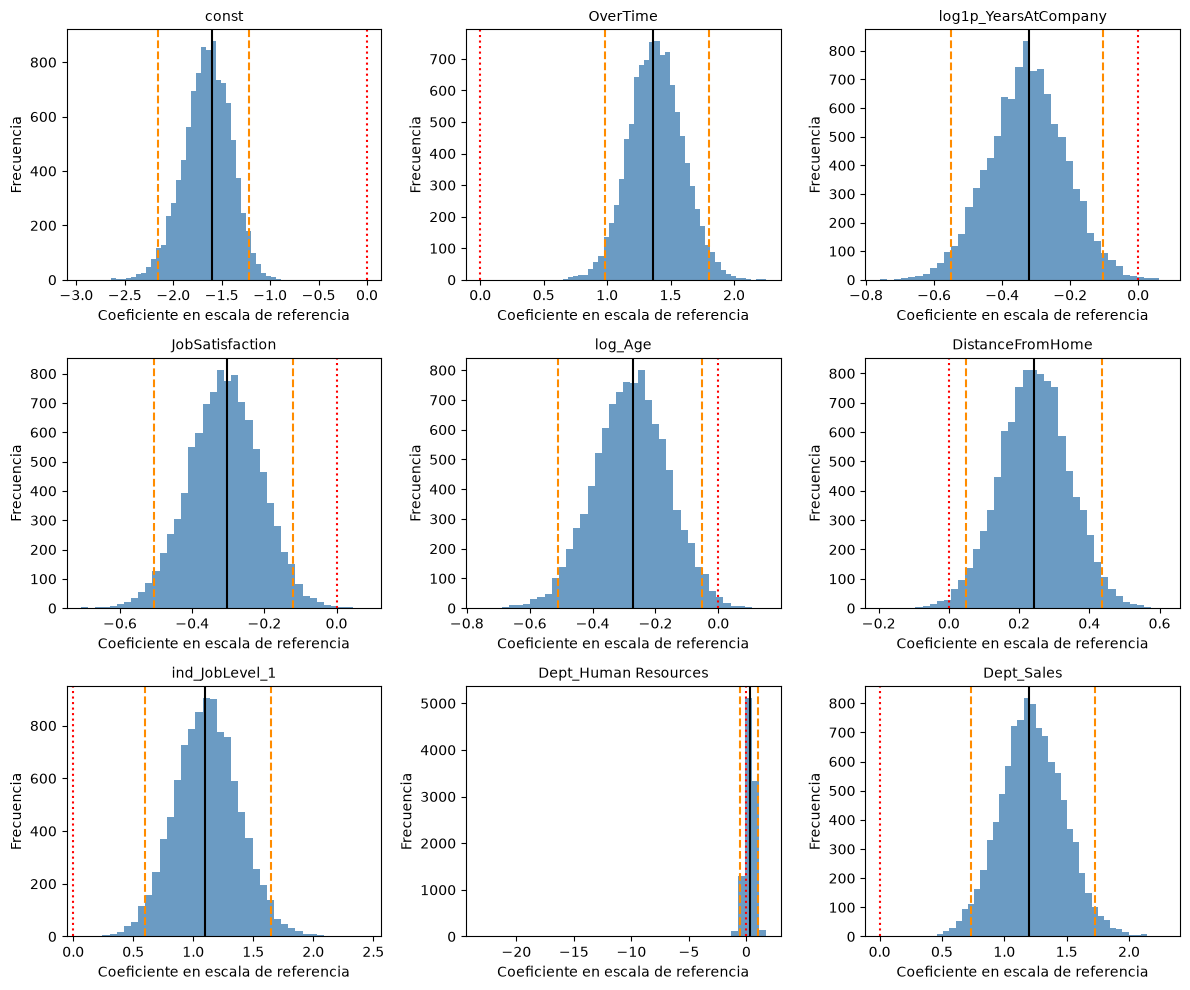

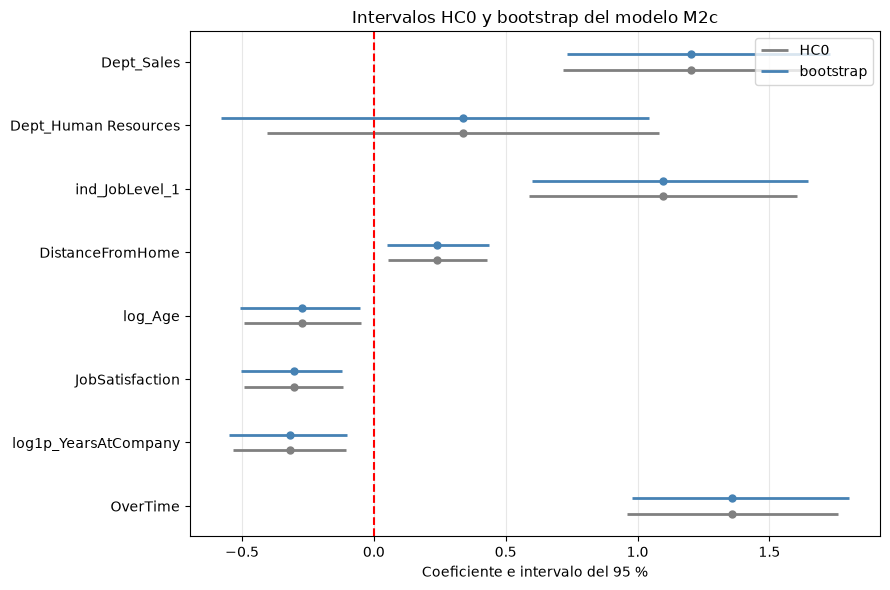

In [8]:
# Distribuciones bootstrap.
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

for ax, termino in zip(axes.flat, TERMINOS_BOOT):
    valores = replicas_bootstrap[termino]
    original = resultado_referencia.params[termino]
    inferior, superior = np.percentile(valores, [2.5, 97.5])

    ax.hist(valores, bins=40, color="steelblue", alpha=0.8)
    ax.axvline(original, color="black", label="Original")
    ax.axvline(0, color="red", linestyle=":")
    ax.axvline(inferior, color="darkorange", linestyle="--")
    ax.axvline(superior, color="darkorange", linestyle="--")
    ax.set_title(termino, fontsize=10)
    ax.set_xlabel("Coeficiente en escala de referencia")
    ax.set_ylabel("Frecuencia")

fig.tight_layout()
fig.savefig(
    FIGURAS / "rodrigo_bootstrap_distribuciones.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

# Comparación de intervalos HC0 y bootstrap, sin intercepto.
tabla_grafico = tabla_bootstrap.loc[
    tabla_bootstrap["Termino"] != "const"
].reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 6))
posiciones = np.arange(len(tabla_grafico))

for desplazamiento, metodo, color in [
    (-0.12, "HC0", "gray"),
    (0.12, "bootstrap", "steelblue"),
]:
    inferior = tabla_grafico[f"IC95 {metodo} inferior"].to_numpy()
    superior = tabla_grafico[f"IC95 {metodo} superior"].to_numpy()
    y = posiciones + desplazamiento

    ax.hlines(
        y, inferior, superior,
        color=color, linewidth=2, label=metodo,
    )
    ax.scatter(
        tabla_grafico["Coeficiente original"],
        y,
        color=color,
        s=25,
    )

ax.axvline(0, color="red", linestyle="--")
ax.set_yticks(posiciones, tabla_grafico["Termino"])
ax.set_xlabel("Coeficiente e intervalo del 95 %")
ax.set_title("Intervalos HC0 y bootstrap del modelo M2c")
ax.legend()
ax.grid(axis="x", alpha=0.3)

fig.tight_layout()
fig.savefig(
    FIGURAS / "rodrigo_bootstrap_comparacion_intervalos.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
plt.close(fig)

## 6: Comparación entre M1, M2c y las estrategias de imputación

In [9]:
ESTRATEGIAS = ["eliminacion", "mediana", "regresion"]

datasets = {
    estrategia: {
        conjunto: pd.read_csv(
            DIRECTORIO_S3 / "datos" / f"{estrategia}_{conjunto}.csv",
            index_col="EmployeeNumber",
        )
        for conjunto in ["train", "test"]
    }
    for estrategia in ESTRATEGIAS
}

ids_comunes = datasets["eliminacion"]["test"].index
assert len(ids_comunes) == 390

for estrategia in ESTRATEGIAS:
    assert datasets[estrategia]["train"].index.is_unique
    assert datasets[estrategia]["test"].index.is_unique
    assert set(ids_comunes) <= set(datasets[estrategia]["test"].index)

assert len(datasets["eliminacion"]["train"]) == 933
assert len(datasets["mediana"]["train"]) == 1029
assert len(datasets["regresion"]["train"]) == 1029

modelos_sensibilidad = {
    "M1": ESPECIFICACIONES["M1"],
    MODELO_FINAL: config_final["variables"],
}

ajustes_sensibilidad = {}
filas_sensibilidad = []
predicciones_sensibilidad = []

for nombre, variables in modelos_sensibilidad.items():
    for estrategia, conjuntos in datasets.items():
        entrenamiento = conjuntos["train"]
        prueba = conjuntos["test"]

        y_ajuste = codificar_objetivo(entrenamiento["Attrition"])

        # Ajustar escalado y pesos con el entrenamiento de cada estrategia.
        preparador = PreparadorDiseno(variables).ajustar(entrenamiento)
        X_ajuste = preparador.transformar(entrenamiento)

        resultado = ajustar_logit(
            X_ajuste,
            y_ajuste,
            pesos_balanceados(y_ajuste),
        )

        ajustes_sensibilidad[(nombre, estrategia)] = {
            "resultado": resultado,
            "preparador": preparador,
        }

        for etiqueta, datos in [
            ("Entrenamiento", entrenamiento),
            ("Prueba disponible", prueba),
            ("Prueba comun", prueba.loc[ids_comunes]),
        ]:
            X = preparador.transformar(datos)
            y = codificar_objetivo(datos["Attrition"])
            probabilidades = resultado.predict(X)

            filas_sensibilidad.append({
                "Modelo": nombre,
                "Estrategia": estrategia,
                "Conjunto": etiqueta,
                "N entrenamiento": len(entrenamiento),
                **calcular_metricas(y, probabilidades),
            })

            if etiqueta == "Prueba disponible":
                predicciones_sensibilidad.append(pd.DataFrame({
                    "EmployeeNumber": datos.index,
                    "Modelo": nombre,
                    "Estrategia": estrategia,
                    "Attrition": y.to_numpy(),
                    "Probabilidad_salida": probabilidades.to_numpy(),
                }))

sensibilidad_imputacion = pd.DataFrame(filas_sensibilidad)

sensibilidad_imputacion.to_csv(
    RESULTADOS / "rodrigo_sensibilidad_imputacion_metricas.csv",
    index=False,
)

pd.concat(predicciones_sensibilidad, ignore_index=True).to_csv(
    RESULTADOS / "rodrigo_sensibilidad_imputacion_predicciones.csv",
    index=False,
)

# M2c excluye ingreso: mediana y regresión deben dar el mismo ajuste.
np.testing.assert_allclose(
    ajustes_sensibilidad[(MODELO_FINAL, "mediana")]["resultado"].params,
    ajustes_sensibilidad[(MODELO_FINAL, "regresion")]["resultado"].params,
    rtol=1e-7,
    atol=1e-10,
)

display(
    sensibilidad_imputacion.loc[
        sensibilidad_imputacion["Conjunto"] == "Prueba comun",
        [
            "Modelo", "Estrategia", "N entrenamiento",
            "Registros", "Accuracy", "Precision", "Recall", "F1", "AUC",
        ],
    ].round(4)
)

print("Subconjunto común identificado por EmployeeNumber:", len(ids_comunes))

,Modelo,Estrategia,N entrenamiento,Registros,Accuracy,Precision,Recall,F1,AUC
2,M1,eliminacion,933,390,0.7359,0.3623,0.7692,0.4926,0.8027
5,M1,mediana,1029,390,0.7256,0.3521,0.7692,0.4831,0.8036
8,M1,regresion,1029,390,0.7333,0.3597,0.7692,0.4902,0.8034
11,M2c,eliminacion,933,390,0.7462,0.3672,0.7231,0.4870,0.7963
14,M2c,mediana,1029,390,0.7564,0.3828,0.7538,0.5078,0.8017
17,M2c,regresion,1029,390,0.7564,0.3828,0.7538,0.5078,0.8017


Subconjunto común identificado por EmployeeNumber: 390


### Comparación de coeficientes e intervalos

Los coeficientes de cada estrategia se convierten a una escala común:
la media y desviación estándar del entrenamiento imputado por regresión.
También se transforma el intercepto y la matriz de covarianza HC0.

Así, las diferencias de coeficientes y odds ratios no se confunden
con cambios en la unidad de estandarización. Los intervalos son
condicionales a cada ajuste y no incorporan toda la incertidumbre
de imputación ni de selección.

In [10]:
filas_coeficientes = []
filas_escalas = []

for nombre, variables in modelos_sensibilidad.items():
    referencia = PreparadorDiseno(variables).ajustar(
        datasets["regresion"]["train"]
    )

    escala = referencia.parametros()
    escala.insert(0, "Modelo", nombre)
    filas_escalas.append(escala)

    for estrategia in ESTRATEGIAS:
        ajuste = ajustes_sensibilidad[(nombre, estrategia)]
        resultado = ajuste["resultado"]
        preparador = ajuste["preparador"]

        terminos = list(resultado.params.index)
        transformacion = np.eye(len(terminos))

        for variable in preparador.numericas:
            j = terminos.index(variable)
            de = preparador.desviaciones_[variable]

            transformacion[j, j] = (
                referencia.desviaciones_[variable] / de
            )
            transformacion[0, j] = (
                referencia.medias_[variable]
                - preparador.medias_[variable]
            ) / de

        beta = transformacion @ resultado.params.to_numpy()

        covarianza = (
            transformacion
            @ np.asarray(resultado.cov_params())
            @ transformacion.T
        )

        errores = np.sqrt(np.diag(covarianza))
        inferior = beta - 1.959963984540054 * errores
        superior = beta + 1.959963984540054 * errores

        for j, termino in enumerate(terminos):
            filas_coeficientes.append({
                "Modelo": nombre,
                "Estrategia": estrategia,
                "Termino": termino,
                "Coeficiente": beta[j],
                "Error estandar HC0": errores[j],
                "IC95 inferior": inferior[j],
                "IC95 superior": superior[j],
                "OR": np.exp(beta[j]),
                "IC95 OR inferior": np.exp(inferior[j]),
                "IC95 OR superior": np.exp(superior[j]),
            })

coeficientes_sensibilidad = pd.DataFrame(filas_coeficientes)

coeficientes_sensibilidad.to_csv(
    RESULTADOS / "rodrigo_sensibilidad_imputacion_coeficientes.csv",
    index=False,
)

pd.concat(filas_escalas, ignore_index=True).to_csv(
    RESULTADOS / "rodrigo_sensibilidad_escala_referencia.csv",
    index=False,
)

display(
    coeficientes_sensibilidad.loc[
        coeficientes_sensibilidad["Termino"] == "MonthlyIncome"
    ].round(4)
)

print("Coeficientes e intervalos guardados en una escala común.")

,Modelo,Estrategia,Termino,Coeficiente,Error estandar HC0,IC95 inferior,IC95 superior,OR,IC95 OR inferior,IC95 OR superior
2,M1,eliminacion,MonthlyIncome,-0.4129,0.1102,-0.6289,-0.1969,0.6617,0.5332,0.8213
7,M1,mediana,MonthlyIncome,-0.3983,0.1105,-0.6149,-0.1818,0.6714,0.5407,0.8338
12,M1,regresion,MonthlyIncome,-0.3769,0.1087,-0.5898,-0.1639,0.6860,0.5544,0.8488


Coeficientes e intervalos guardados en una escala común.


### Interpretación del impacto de la imputación

En M1, el ingreso mantiene una asociación negativa ajustada con la
salida bajo las tres estrategias. Los OR, expresados en una escala
común, son 0,662 con eliminación, 0,671 con mediana y 0,686 con
regresión. Los tres intervalos HC0 del 95 % excluyen 1.

En los 390 empleados comunes de prueba, el AUC de M1 varía entre
0,8027 y 0,8036. Estos resultados muestran poca sensibilidad del
desempeño y conservación de la dirección del ingreso en los escenarios
examinados; no demuestran equivalencia formal entre estrategias.

En M2c, mediana y regresión producen resultados idénticos porque el
ingreso no forma parte de su especificación y ambas conservan las
mismas filas. La eliminación modifica el conjunto de entrenamiento,
por lo que puede cambiar el ajuste incluso sin incluir ingreso.

Se mantiene regresión como estrategia principal por la evidencia
predictiva de imputación obtenida en entrenamiento. La evaluación
de prueba se utiliza para describir sensibilidad, no para cambiar
retroactivamente esa elección.

Los resultados del subconjunto común no deben compararse directamente
con los del conjunto completo de 441 empleados, porque cambia la
composición de la muestra evaluada.